# Elderly workforce potential in Odisha: LASI Wave 1 + NCP projections + GSVA
Cells run top to bottom. Section 5 (diagnostics) is optional; set `run_diagnostics = True` to print it.

In [39]:
# %% 1. Imports
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)

In [40]:
# %% 2. Parameters
lasi_path = Path("3_LASI_W1_Individual_data.dta")
lasi_cache = Path("lasi_subset.parquet")   # all-state extract of use_cols; rebuilt automatically when stale
state_name = "Odisha"

ncp_path = "Pop.csv"                       # long format: age, year, sex, pop
ncp_unit = 1                               # 1 if persons, 1000 if thousands, 1e5 if lakh

es_path = "es.csv"                         # Economic Survey GSVA table: rows = industries, columns = fiscal years
es_year = "2023-24"                        # fiscal year used for GSVA per worker
es_unit_to_crore = 1 / 100                 # file in Rs lakh -> crore (CHECK units)
# Sector workers in es_year, from PLFS Annual Report 2023-24 (July 2023-June 2024), MoSPI,
# usual status (ps+ss), Odisha, rural+urban, persons. Workers = WPR x NCP population x sector share.
plfs_wpr = 0.479                           # Table 17, WPR all ages (15+ is 0.629; all-India all ages 0.437)
plfs_pop_year = 2024                       # NCP population at the survey midpoint (Jan 2024)
_sec = {"A": 48.89, "B": 0.38, "C": 7.17, "D": 0.25, "E": 0.30, "F": 17.96}   # Table 27, % of workers by NIC-2008 section
plfs_sector_pct = {
    "agriculture": _sec["A"],                                 # A: agriculture, forestry & fishing
    "industry": sum(_sec[k] for k in "BCDEF"),                # B-F: mining, manufacturing, utilities, construction
    "services": 100 - sum(_sec.values()),                     # G-T (published sections sum to 25.04)
}                                          # matches the GSVA split: agri | mining + secondary | tertiary

per_to_month = {1: 26.0, 2: 52 / 12, 3: 1.0, 4: 1 / 12}   # 1 Day, 2 Week, 3 Month, 4 Year (confirmed)
full_time_hours_week = 48

jobs_fy24, jobs_2036 = 2.2e7, 2.8e7        # Vision: confirm against full document
lfpr_base, lfpr_2036 = 0.63, 0.74
base_year, target_year = 2024, 2036

fit_def = "core"                           # broad | core | strict
lambdas = [0.0, 0.25, 0.50]
drop_proxy = False                         # decide after seeing rproxy counts
run_diagnostics = False                    # True: print the Section 5 checks

age_bands = ["60-64", "65-69", "70-74", "75-79", "80+"]
age_start = dict(zip(age_bands, [60, 65, 70, 75, 80]))
sectors = ["agriculture", "industry", "services"]

adl = [f"ht{i}" for i in range(401, 407)]
mob = ["ht303", "ht306", "ht307", "ht309", "ht310"]
iadl = [f"ht{i}" for i in range(407, 414)]
sw_cols = ["sw202a", "sw202b", "sw202c", "sw202d", "sw202e"]

In [41]:
# %% 3. Load LASI (only the needed columns, as raw numeric codes; cached to parquet)
use_cols = (["prim_key", "hhid", "stateid", "residence", "mpce_quintile",
             "stateindividualweight", "rproxy", "dm003", "dm005",
             "we004", "we005", "we018", "we020", "we020_unit", "we023", "we026", "we201", "we412"]
            + sw_cols + mob + adl + iadl)


def load_lasi(path, cache, cols):
    """Read `cols` from the .dta once (raw codes, chunked), cache all states to parquet."""
    if cache.exists() and cache.stat().st_mtime > path.stat().st_mtime:
        d = pd.read_parquet(cache)
        if set(cols) <= set(d.columns):
            return d[cols]
    # convert_categoricals=False returns the numeric codes directly ('3 Month' -> 3),
    # identical to the old label-regex conversion but faster and without string parsing
    d = pd.concat(pd.read_stata(path, columns=cols, convert_categoricals=False, chunksize=20000),
                  ignore_index=True)
    d.to_parquet(cache, index=False)
    return d


with pd.io.stata.StataReader(lasi_path) as rdr:            # state code from the value labels
    state_labels = next(v for k, v in rdr.value_labels().items() if k.startswith("stateid"))
state_code = next(c for c, lab in state_labels.items() if lab.strip().lower() == state_name.lower())

lasi = load_lasi(lasi_path, lasi_cache, use_cols)
lasi = lasi[lasi["stateid"] == state_code].copy()
lasi = lasi.rename(columns={"stateindividualweight": "w", "we020_unit": "we020_per"})
lasi = lasi[lasi["w"].notna()].reset_index(drop=True)
lasi["psu"] = lasi["hhid"].astype(str)      # stopgap: no PSU in the file, CIs will be too narrow
lasi["strata"] = lasi["residence"]
print(f"{state_name} (code {state_code}):", lasi.shape)

Odisha (code 21): (2917, 43)


In [42]:
# %% 4a. NCP population (long: age, year, sex, pop)
ncp = pd.read_csv(ncp_path, encoding="utf-8-sig")
# Excel turned '5-9' into '05-Sep' and '10-14' into 'Oct-14'; recover the band start
months = {m: i for i, m in enumerate(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                                      "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], 1)}
age_txt = ncp["age"].astype(str).str.strip()
lead_month = age_txt.str[:3].map(months)
ncp["age_start"] = lead_month.fillna(pd.to_numeric(age_txt.str.extract(r"(\d+)")[0], errors="coerce"))
ncp["sex"] = ncp["sex"].astype(str).str.strip().str[0].str.upper().map({"M": 1, "F": 2})
ncp["year"] = pd.to_numeric(ncp["year"], errors="coerce")
ncp["pop"] = pd.to_numeric(ncp["pop"], errors="coerce") * ncp_unit
ncp = ncp.dropna(subset=["age_start", "year", "sex"])
ncp["age_start"] = ncp["age_start"].clip(upper=80).astype(int)   # 80+ band
ncp["sex"] = ncp["sex"].astype(int)
ncp_wide = ncp.pivot_table(index="year", columns=["sex", "age_start"], values="pop", aggfunc="sum")

print(sorted(ncp["age_start"].unique()))                   # expect 0, 5, ..., 80
print(ncp_wide.T.groupby(level="sex").sum().T.loc[[2021, 2026, 2031, 2036]])  # 2036 total about 49 million

[np.int64(0), np.int64(5), np.int64(10), np.int64(15), np.int64(20), np.int64(25), np.int64(30), np.int64(35), np.int64(40), np.int64(45), np.int64(50), np.int64(55), np.int64(60), np.int64(65), np.int64(70), np.int64(75), np.int64(80)]
sex          1         2
year                    
2021  23002000  22694000
2026  23691000  23454000
2031  24204000  24055000
2036  24542000  24484000


In [43]:
# %% 4b. Population helpers (NCP)
def ncp_at(year):
    """Population by (sex, age_start) in `year`, linear interpolation between projection years."""
    years = ncp_wide.index.to_numpy()
    if year in years:
        return ncp_wide.loc[year]
    y0, y1 = years[years < year].max(), years[years > year].min()
    a, b = ncp_wide.loc[y0], ncp_wide.loc[y1]
    return a + (b - a) * (year - y0) / (y1 - y0)


band_of_start = {v: k for k, v in age_start.items()}


def bands(pop):
    """60+ population by sex x age band."""
    p = pop.rename("pop").reset_index()
    p["age_band"] = p["age_start"].map(band_of_start)
    return p.dropna(subset=["age_band"]).groupby(["sex", "age_band"], as_index=False)["pop"].sum()


def pop_between(pop, lo, hi=None):
    a = pop.index.get_level_values("age_start")
    sel = (a >= lo) & ((a <= hi) if hi is not None else True)
    return pop[sel].sum()


pop_T, pop_B, pop_26 = ncp_at(target_year), ncp_at(base_year), ncp_at(2026)
bands_T, bands_B = bands(pop_T), bands(pop_B)

In [44]:
# %% 5. Economic Survey GSVA and PLFS workers by sector
g = pd.read_csv(es_path, index_col=0, encoding="utf-8-sig")
g.columns = [" ".join(str(c).split()) for c in g.columns]  # tidy split / padded headers
g.index = [" ".join(str(i).split()) for i in g.index]
es_col = next(c for c in g.columns if c.startswith(es_year))
g_year = pd.to_numeric(g[es_col], errors="coerce") * es_unit_to_crore


def gsva_row(name):
    return g_year[g_year.index.str.lower().str.startswith(name.lower())].iloc[0]


plfs_pop = pop_between(ncp_at(plfs_pop_year), 0)
workers_es = {j: plfs_wpr * plfs_pop * plfs_sector_pct[j] / 100 for j in sectors}
print(f"PLFS workers {es_year}: {sum(workers_es.values()):,.0f} (WPR {plfs_wpr:.1%} x pop {plfs_pop:,.0f})")

es = pd.DataFrame({
    "gsva_cr": [gsva_row("Agriculture, Forestry"),
                gsva_row("Mining") + gsva_row("Secondary"),
                gsva_row("Tertiary")],                     # CHECK: services total row
    "workers": [workers_es[j] for j in sectors],
}, index=pd.Index(sectors, name="sector"))
total = gsva_row("TOTAL GSVA")
print(es)
print("sum of sectors:", round(es["gsva_cr"].sum()), "| file total:", round(total))
assert abs(es["gsva_cr"].sum() - total) / total < 0.01, "sectors do not add up to the total"
workers_ok = es["workers"].notna().all()
print("workers filled in:", workers_ok)

PLFS workers 2023-24: 22,304,827 (WPR 47.9% x pop 46,565,400)
               gsva_cr       workers
sector                              
agriculture   70278.34  1.090483e+07
industry     211608.07  5.812638e+06
services     165700.48  5.587359e+06
sum of sectors: 447587 | file total: 447587
workers filled in: True


In [45]:
# %% 6. Diagnostics (optional): run once and paste the output
if run_diagnostics:
    print(f"{state_name} rows:", len(lasi), "| 60+:", (lasi["dm005"] >= 60).sum())
    print("weight: min/median/max", lasi["w"].min(), lasi["w"].median(), lasi["w"].max())
    print("age range:", lasi["dm005"].min(), lasi["dm005"].max())
    print("households:", lasi["hhid"].nunique(), "| persons per household (mean):",
          round(len(lasi) / lasi["hhid"].nunique(), 2))
    print()
    for c in ["dm003", "residence", "rproxy", "we004", "we005", "we201",
              "we020_per", "we023", "we412", "sw202a", "sw202b"]:
        print(lasi[c].value_counts(dropna=False).sort_index().head(15).to_string(), "\n")

    # difficulty items (1 = yes, 2 = no assumed): share with difficulty among 60+
    old_ = lasi.loc[lasi["dm005"] >= 60, mob + adl + iadl]
    chk = pd.DataFrame({"n_1": old_.eq(1).sum(), "n_2": old_.eq(2).sum(),
                        "n_other_or_missing": (~old_.isin([1, 2])).sum()})
    chk["pct_1_of_valid"] = (100 * chk["n_1"] / (chk["n_1"] + chk["n_2"])).round(1)
    print(chk.to_string(), "\n")

    # earnings by period (should rise day -> year)
    wk_ = lasi[(lasi["we004"] == 1) | (lasi["we005"] == 1)]
    print(wk_.groupby("we020_per")["we020"].describe()[["count", "25%", "50%", "75%"]].to_string())
    print("workers with earnings missing:", wk_["we020"].isna().sum(), "of", len(wk_))
    print("hours missing:", wk_["we018"].isna().sum(), "| months missing:", wk_["we026"].isna().sum(), "\n")

    # population check
    for y in [2021, 2024, 2026, 2031, 2036]:
        p = ncp_at(y)
        print(y, "| total:", f"{pop_between(p, 0):,.0f}", "| 15-59:", f"{pop_between(p, 15, 55):,.0f}",
              "| 60+:", f"{pop_between(p, 60):,.0f}",
              "| 60+ share:", round(100 * pop_between(p, 60) / pop_between(p, 0), 1))

In [46]:
# %% 7. Construct variables
df = lasi.copy()
if drop_proxy:
    df = df[df["rproxy"] != 1]                # CHECK: proxy coding

df[adl + mob + iadl] = df[adl + mob + iadl].where(df[adl + mob + iadl].isin([1, 2]))  # 1 = difficulty, 2 = no

df["sex"] = df["dm003"]                       # CHECK: 1 male, 2 female
df["age_band"] = pd.cut(df["dm005"], [59, 64, 69, 74, 79, 120], labels=age_bands)

fit_items = {"broad": adl, "core": adl + mob, "strict": adl + mob + iadl}
df["working"] = ((df["we004"] == 1) | (df["we005"] == 1)).astype(int)    # CHECK codes
df["seeking"] = ((df["we201"] == 1) | (df["we005"] == 2)).astype(int)    # CHECK codes
wk_flag = df["working"] == 1
for name, cols in fit_items.items():
    items = df[cols]
    complete = items.notna().all(axis=1)
    fit = ~items.eq(1).any(axis=1)
    df[f"F_{name}"] = (fit & wk_flag).astype(float).where(complete)      # fit, working
    df[f"U_{name}"] = (fit & ~wk_flag).astype(float).where(complete)     # fit, not working
    df[f"N_{name}"] = (~fit & wk_flag).astype(float).where(complete)     # working, not fit

df["social_pension"] = df[sw_cols].eq(1).any(axis=1).astype(int)        # CHECK: 1 = yes
df["work_pension"] = (df["we412"] == 1).astype(int)
df["any_pension"] = (df["social_pension"] | df["work_pension"]).astype(int)

print(f"{state_name} 60+ (unweighted n):", (df["dm005"] >= 60).sum())

Odisha 60+ (unweighted n): 1237


In [47]:
# %% 8. Survey-weighted shares by age band and sex (vectorised Taylor linearisation)
psu_key = pd.MultiIndex.from_arrays([df["strata"], df["psu"]])
domains = [(s, ab) for s in sorted(df["sex"].dropna().unique()) for ab in age_bands]
dom_mat = np.column_stack([((df["sex"] == s) & (df["age_band"] == ab)).to_numpy() for s, ab in domains])
dom_n = dom_mat.sum(axis=0)


def wshares(y):
    """Weighted share of column y in every domain, with 95% CI from strata/PSU linearisation."""
    yv = df[y].to_numpy(dtype=float)
    ok = ~np.isnan(yv)
    yy = np.where(ok, yv, 0.0)
    wd = df["w"].to_numpy(dtype=float)[:, None] * (dom_mat & ok[:, None])   # rows x domains
    sw = wd.sum(axis=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        p = (wd * yy[:, None]).sum(axis=0) / sw
        z = wd * (yy[:, None] - p) / sw
    zp = pd.DataFrame(z, index=psu_key).groupby(level=[0, 1]).sum()        # PSU totals
    n_h = zp.index.get_level_values(0).map(zp.groupby(level=0).size()).to_numpy(dtype=float)
    fac = np.where(n_h > 1, n_h / np.maximum(n_h - 1, 1), 0.0)              # single-PSU strata skipped
    dev2 = (zp - zp.groupby(level=0).transform("mean")).to_numpy() ** 2
    se = np.sqrt((dev2 * fac[:, None]).sum(axis=0))
    p = np.where(sw > 0, p, np.nan)
    return p, np.clip(p - 1.96 * se, 0, None), np.clip(p + 1.96 * se, None, 1)


share_vars = {"working": "working", "seeking": "seeking", "any_pension": "any_pension"}


def age_sex_table(fit):
    t = pd.DataFrame(domains, columns=["sex", "age_band"])
    t["n"] = dom_n
    for label, var in {"F": f"F_{fit}", "U": f"U_{fit}", "N": f"N_{fit}", **share_vars}.items():
        t[label], t[label + "_lo"], t[label + "_hi"] = wshares(var)
    return t


tables = {fit: age_sex_table(fit) for fit in fit_items}   # reused by the sensitivity section
ind = tables[fit_def]
print(ind.round(3).to_string(index=False))

 sex age_band   n     F  F_lo  F_hi     U  U_lo  U_hi     N  N_lo  N_hi  working  working_lo  working_hi  seeking  seeking_lo  seeking_hi  any_pension  any_pension_lo  any_pension_hi
   1    60-64 203 0.382 0.309 0.456 0.074 0.038 0.111 0.405 0.331 0.478    0.789       0.732       0.846    0.018         0.0       0.035        0.284           0.217           0.351
   1    65-69 159 0.273 0.194 0.352 0.102 0.052 0.152 0.431 0.346 0.516    0.708       0.633       0.782    0.004         0.0       0.012        0.557           0.472           0.642
   1    70-74 100 0.197 0.113 0.282 0.110 0.049 0.170 0.307 0.205 0.408    0.504       0.398       0.609    0.040         0.0       0.089        0.573           0.470           0.675
   1    75-79  72 0.099 0.017 0.181 0.109 0.032 0.185 0.220 0.118 0.322    0.314       0.192       0.436    0.000         0.0       0.000        0.770           0.661           0.879
   1      80+  67 0.050 0.001 0.098 0.162 0.061 0.264 0.163 0.070 0.256    0.213     

In [48]:
# %% 9. Productivity inputs: sector mix m, hours factor h, relative productivity phi
wk = df[wk_flag].copy()
wk["sector"] = pd.cut(wk["we023"], [0, 1, 6, np.inf], labels=sectors, right=True)  # CHECK we023 codes; NaN stays NaN
monthly = wk["we020"] * wk["we020_per"].map(per_to_month)
wk["hourly"] = monthly / (wk["we018"] * 52 / 12)
wk["hourly"] = wk["hourly"].clip(*wk["hourly"].quantile([0.01, 0.99]))
wk["h"] = (wk["we018"] * wk["we026"] / (full_time_hours_week * 12)).clip(0, 1)


def wmean(x, w):
    ok = x.notna() & w.notna()
    return np.average(x[ok], weights=w[ok]) if ok.any() else np.nan


def sector_hourly(d):
    return d.groupby("sector", observed=False)[["hourly", "w"]].apply(lambda s: wmean(s["hourly"], s["w"]))


w60 = wk[wk["dm005"] >= 60]
w4559 = wk[wk["dm005"].between(45, 59)]
m = (w60.groupby("sector", observed=False)["w"].sum() / w60["w"].sum()).reindex(sectors).fillna(0)
h = wmean(w60["h"], w60["w"])
phi_j = (sector_hourly(w60) / sector_hourly(w4559)).reindex(sectors)
ok_j = phi_j.notna()
phi = (m[ok_j] * phi_j[ok_j]).sum() / m[ok_j].sum()
print("sector mix:", m.round(3).to_dict(), "| h =", round(h, 3), "| phi =", round(phi, 3))
print("workers with missing sector code:", wk["sector"].isna().sum())

sector mix: {'agriculture': 0.7590000033378601, 'industry': 0.041999999433755875, 'services': 0.19599999487400055} | h = 0.503 | phi = 1.031
workers with missing sector code: 2


In [49]:
# %% 10. Employment model
def workers(t, pop60, suffix=""):
    x = t.merge(pop60, on=["sex", "age_band"])
    L0 = (x["pop"] * (x["F" + suffix] + x["N" + suffix])).sum()    # baseline elderly workers
    U = (x["pop"] * x["U" + suffix]).sum()                         # untapped pool
    return L0, U


L0, U = workers(ind, bands_T)
L0_base, _ = workers(ind, bands_B)
scen = pd.DataFrame({"lambda": lambdas})
scen["added"] = scen["lambda"] * U
scen["elderly_workers"] = L0 + scen["added"]
print(f"Baseline elderly workers {target_year}: {L0:,.0f} | untapped pool: {U:,.0f}")

Baseline elderly workers 2036: 3,005,019 | untapped pool: 1,156,819


In [50]:
# %% 11. Comparison with the Vision
pop15 = pop_between(pop_T, 15)
loss_15_59 = pop_between(pop_T, 15, 55) - pop_between(pop_26, 15, 55)    # 2026 -> target
scen["gain_vs_base_year"] = scen["elderly_workers"] - L0_base
scen["share_of_vision_jobs_increase"] = scen["gain_vs_base_year"] / (jobs_2036 - jobs_fy24)
scen["elderly_pp_of_15plus"] = 100 * scen["elderly_workers"] / pop15
scen["vision_pp_rise_needed"] = 100 * (lfpr_2036 - lfpr_base)
scen["change_pop_15_59_2026_T"] = loss_15_59
scen["added_vs_15_59_change"] = scen["added"] / abs(loss_15_59)
print(scen.round(3).to_string(index=False))

 lambda      added  elderly_workers  gain_vs_base_year  share_of_vision_jobs_increase  elderly_pp_of_15plus  vision_pp_rise_needed  change_pop_15_59_2026_T  added_vs_15_59_change
   0.00      0.000      3005019.240         866515.515                          0.144                 7.557                   11.0                   679000                  0.000
   0.25 289204.726      3294223.966        1155720.241                          0.193                 8.284                   11.0                   679000                  0.426
   0.50 578409.452      3583428.692        1444924.967                          0.241                 9.012                   11.0                   679000                  0.852


In [51]:
# %% 12. Indicative output (GSVA per worker: low / central / high)
y_sector = es["gsva_cr"] * 1e7 / es["workers"]                          # Rs per worker (NaN until filled)
y_all = es["gsva_cr"].sum() * 1e7 / es["workers"].sum(min_count=len(sectors))
per_worker = pd.Series({"low": h * phi * y_sector["agriculture"],
                        "central": h * phi * (m * y_sector).sum(min_count=len(sectors)),
                        "high": y_all})
gsva_total_cr = es["gsva_cr"].sum()
pop_total = pop_between(pop_T, 0)

output = scen[["lambda", "added"]].merge(per_worker.rename("per_worker").rename_axis("case").reset_index(),
                                         how="cross")
output["added_output_cr"] = output["added"] * output["per_worker"] / 1e7      # Rs crore
output["pct_of_latest_gsva"] = 100 * output["added_output_cr"] / gsva_total_cr
output["rs_per_capita"] = output["added_output_cr"] * 1e7 / pop_total
output = output.drop(columns=["added", "per_worker"])
if not workers_ok:
    print("NOTE: fill in the PLFS inputs (Cell 2) to get output estimates; values are NaN until then.")
print(output.pivot_table(index="lambda", columns="case", values="pct_of_latest_gsva", dropna=False).round(3))

case    central   high    low
lambda                       
0.00      0.000  0.000  0.000
0.25      0.410  1.297  0.216
0.50      0.821  2.593  0.432


In [52]:
# %% 13. Sensitivity: fitness definition x CI bound x lambda
rows = []
for fit, t in tables.items():
    for suffix, label in [("", "point"), ("_lo", "lower CI"), ("_hi", "upper CI")]:
        L0_s, U_s = workers(t, bands_T, suffix)
        rows += [{"fit": fit, "bound": label, "lambda": lam, "elderly_workers": L0_s + lam * U_s}
                 for lam in lambdas]
sens = pd.DataFrame(rows)
print(sens.pivot_table(index=["fit", "bound"], columns="lambda", values="elderly_workers").round(0))

lambda                0.00       0.25       0.50
fit    bound                                    
broad  lower CI  2215534.0  3028955.0  3842376.0
       point     3005019.0  4001427.0  4997834.0
       upper CI  3822613.0  5002007.0  6181400.0
core   lower CI  2033484.0  2186578.0  2339672.0
       point     3005019.0  3294224.0  3583429.0
       upper CI  3988159.0  4413474.0  4838790.0
strict lower CI  2035677.0  2180020.0  2324363.0
       point     3005019.0  3283297.0  3561576.0
       upper CI  3985966.0  4398179.0  4810393.0


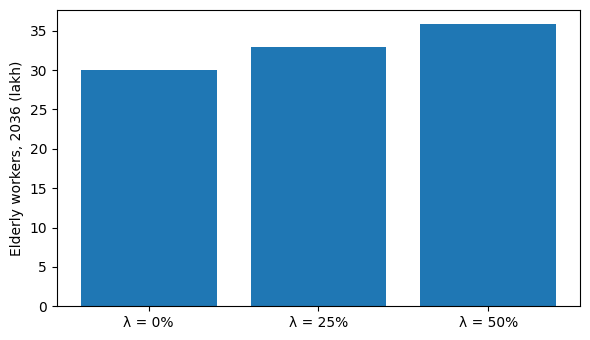

In [53]:
# %% 14. Chart and save
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([f"λ = {l:.0%}" for l in scen["lambda"]], scen["elderly_workers"] / 1e5)
ax.set_ylabel(f"Elderly workers, {target_year} (lakh)")
fig.tight_layout()
fig.savefig("elderly_workers_by_scenario.png", dpi=150)

ind.to_csv("indicators.csv", index=False)
scen.to_csv("scenarios_vision.csv", index=False)
output.to_csv("output_range.csv", index=False)
sens.to_csv("sensitivity.csv", index=False)